# 概要 overview

予測モデルのハイパーパラメータチューニング
Optunaを用いて探索を行う。
交差検証を行い、

作成するモデルは下記
 1. 勾配ブースティング決定木（GBDT）
 2. RandomForest
 3. ニューラルネットワーク（NN）

## ライブラリ読み込み

In [1]:
import torch

# 自作関数 "src"参照
from src.Data_load_And_Preprocess import data_load_and_preprocess
from src.utils import Plot_actual_vs_predict
from src.GBDT_param_tuning import Optimize_lightGBM
from src.RndomForest_param_tuning import Optimize_RndomForest
from src.NN_param_tuning import Optimize_NN

## データの読み込み

データの読み込みおよび訓練データ・テストデータの分割
テストデータは最後の精度比較に使用

In [2]:
X_train, X_test, Y_train, Y_test = data_load_and_preprocess()

Number of samples: 1030
Number of features: 8


## GBDTモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/GBDT/trials_history.csv"に保存


[I 2026-11-22 15:22:42,483] A new study created in memory with name: subrutin_lgbm_tuning


[I 2026-11-22 15:22:43,016] Trial 0 finished with value: 5.270341149104501 and parameters: {'learning_rate': 0.05, 'num_leaves': 44, 'max_depth': 7, 'min_child_samples': 71, 'subsample': 0.86, 'colsample_bytree': 0.99, 'reg_alpha': 0.1, 'reg_lambda': 0.1}. Best is trial 0 with value: 5.270341149104501.


Trial 1 CV Mean [Avg Best Iter: 378.4] Train RMSE: 3.9267 | Valid RMSE: 5.2703 | 


[I 2026-11-22 15:22:43,398] Trial 1 finished with value: 4.902851224513588 and parameters: {'learning_rate': 0.05, 'num_leaves': 98, 'max_depth': 10, 'min_child_samples': 25, 'subsample': 0.9199999999999999, 'colsample_bytree': 0.64, 'reg_alpha': 1.0, 'reg_lambda': 0.01}. Best is trial 1 with value: 4.902851224513588.


Trial 2 CV Mean [Avg Best Iter: 212.2] Train RMSE: 2.7088 | Valid RMSE: 4.9029 | 


[I 2026-11-22 15:22:43,605] Trial 2 finished with value: 5.145299072352938 and parameters: {'learning_rate': 0.1, 'num_leaves': 87, 'max_depth': 4, 'min_child_samples': 22, 'subsample': 0.62, 'colsample_bytree': 0.84, 'reg_alpha': 1.0, 'reg_lambda': 0.1}. Best is trial 1 with value: 4.902851224513588.


... (2 outputs left out)

Trial 4 CV Mean [Avg Best Iter: 943.8] Train RMSE: 4.7380 | Valid RMSE: 5.7797 | 


[I 2026-11-22 15:22:44,955] Trial 4 finished with value: 5.7326844336326275 and parameters: {'learning_rate': 0.1, 'num_leaves': 49, 'max_depth': 8, 'min_child_samples': 84, 'subsample': 0.8999999999999999, 'colsample_bytree': 0.64, 'reg_alpha': 0.1, 'reg_lambda': 10.0}. Best is trial 1 with value: 4.902851224513588.


Trial 5 CV Mean [Avg Best Iter: 172.0] Train RMSE: 4.6499 | Valid RMSE: 5.7327 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 1
ベストイテレーション（平均）: 212.2 ラウンド
ベスト検証 RMSE: 4.9029
ベスト訓練 RMSE: 2.7088
ベストパラメータ:
  - learning_rate: 0.05
  - num_leaves: 98
  - max_depth: 10
  - min_child_samples: 25
  - subsample: 0.9199999999999999
  - colsample_bytree: 0.64
  - reg_alpha: 1.0
  - reg_lambda: 0.01


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\GBDT_param_tuning.py:147: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


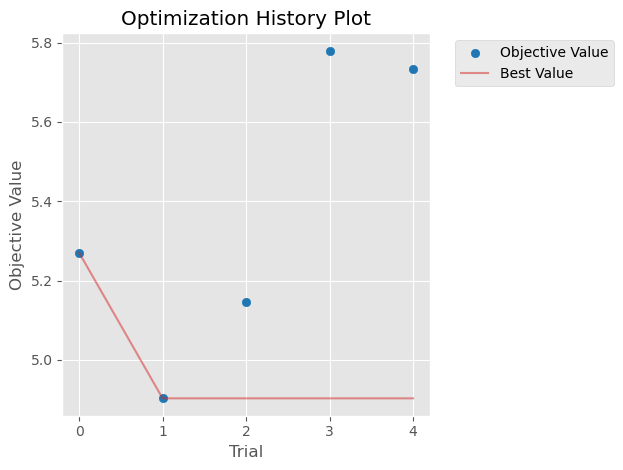

処理時間: 2.89秒


In [5]:
trial_n =5 #Optuna探索試行回数

Optimize_lightGBM(trial_n, X_train, Y_train)

## RndomForestモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/RandomForest/trials_history.csv"に保存


[I 2026-11-22 18:08:23,275] A new study created in memory with name: subrutin_lgbm_tuning


[I 2026-11-22 18:08:25,892] Trial 0 finished with value: 9.06804761041419 and parameters: {'max_features': 0.4325775193300805, 'max_depth': 6, 'min_samples_leaf': 17, 'min_samples_split': 20}. Best is trial 0 with value: 9.06804761041419.


Trial 1  Train RMSE: 8.3016 | Valid RMSE: 9.0680 | 


[I 2026-11-22 18:08:29,835] Trial 1 finished with value: 6.941506622725133 and parameters: {'max_features': 0.571793571364571, 'max_depth': 9, 'min_samples_leaf': 4, 'min_samples_split': 9}. Best is trial 1 with value: 6.941506622725133.


Trial 2  Train RMSE: 5.2606 | Valid RMSE: 6.9415 | 


[I 2026-11-22 18:08:33,338] Trial 2 finished with value: 8.29458410424007 and parameters: {'max_features': 0.6611280060903186, 'max_depth': 12, 'min_samples_leaf': 11, 'min_samples_split': 19}. Best is trial 1 with value: 6.941506622725133.


... (2 outputs left out)

Trial 4  Train RMSE: 7.9290 | Valid RMSE: 8.7965 | 


[I 2026-11-22 18:08:39,791] Trial 4 finished with value: 9.316427619222061 and parameters: {'max_features': 0.6207760732489374, 'max_depth': 20, 'min_samples_leaf': 20, 'min_samples_split': 18}. Best is trial 1 with value: 6.941506622725133.


Trial 5  Train RMSE: 8.6130 | Valid RMSE: 9.3164 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 1
ベスト検証 RMSE: 6.9415
ベスト訓練 RMSE: 5.2606
ベストパラメータ:
  - max_features: 0.571793571364571
  - max_depth: 9
  - min_samples_leaf: 4
  - min_samples_split: 9


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\RndomForest_param_tuning.py:141: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


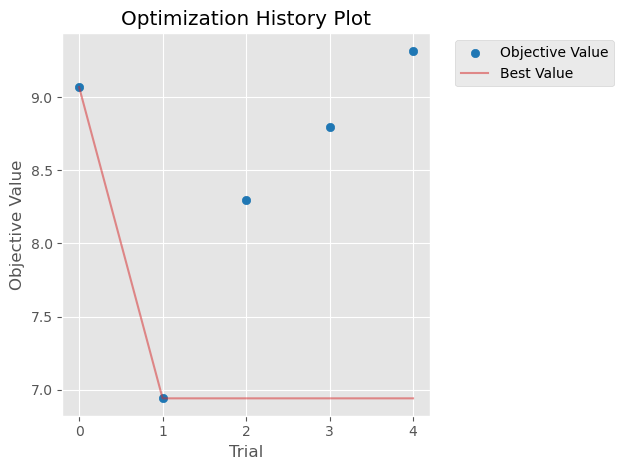

処理時間: 16.94秒


In [ ]:
trial_n =5 #Optuna探索試行回数

Optimize_RndomForest(trial_n, X_train, Y_train)

[I 2026-11-23 10:23:25,431] A new study created in memory with name: subrutin_lgbm_tuning


Device: cpu

Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=96, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=96, out_features=48, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.4, inplace=False)
    (6): Linear(in_features=48, out_features=16, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.4, inplace=False)
    (9): Linear(in_features=16, out_features=16, bias=True)
    (10): ReLU()
    (11): Dropout(p=0.4, inplace=False)
    (12): Linear(in_features=16, out_features=1, bias=True)
  )
)
--- 学習開始 ---
Epoch [10/300] Train Loss: 0.7261 | Valid Loss: 0.5908 | 
Epoch [20/300] Train Loss: 0.6479 | Valid Loss: 0.5123 | 
Epoch [30/300] Train Loss: 0.5958 | Valid Loss: 0.4763 | 

Early Stopping: Epoch 30
--- 学習完了 ---
処理時間: 4.63秒
 Trial 1 | 1/5 fold finished
Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=96, bias=True)
    (1): ReLU()
    

[I 2026-11-23 10:23:51,088] Trial 0 finished with value: 7.828795122694993 and parameters: {'n_layers': 4, 'hidden_dim_0': 96, 'hidden_dim_1': 48, 'hidden_dim_2': 16, 'hidden_dim_3': 16, 'drop_rate': 0.4}. Best is trial 0 with value: 7.828795122694993.


Trial 1 CV Mean [Avg Best Iter: 32.6] Train RMSE: 7.3175 | Valid RMSE: 7.8288 | 

Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=192, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=192, out_features=176, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.4, inplace=False)
    (6): Linear(in_features=176, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.4, inplace=False)
    (9): Linear(in_features=128, out_features=1, bias=True)
  )
)
--- 学習開始 ---
Epoch [10/300] Train Loss: 0.5335 | Valid Loss: 0.4205 | 
Epoch [20/300] Train Loss: 0.4613 | Valid Loss: 0.3881 | 
Epoch [30/300] Train Loss: 0.4465 | Valid Loss: 0.3782 | 

Early Stopping: Epoch 30
--- 学習完了 ---
処理時間: 5.08秒
 Trial 2 | 1/5 fold finished
Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=192, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3)

[I 2026-11-23 10:24:20,304] Trial 1 finished with value: 6.380050202024401 and parameters: {'n_layers': 3, 'hidden_dim_0': 192, 'hidden_dim_1': 176, 'hidden_dim_2': 128, 'drop_rate': 0.4}. Best is trial 1 with value: 6.380050202024401.


Trial 2 CV Mean [Avg Best Iter: 29.8] Train RMSE: 5.3999 | Valid RMSE: 6.3801 | 

Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=224, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=224, out_features=224, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.5, inplace=False)
    (6): Linear(in_features=224, out_features=1, bias=True)
  )
)
--- 学習開始 ---
Epoch [10/300] Train Loss: 0.5503 | Valid Loss: 0.4585 | 
Epoch [20/300] Train Loss: 0.5099 | Valid Loss: 0.3960 | 
Epoch [30/300] Train Loss: 0.4552 | Valid Loss: 0.3838 | 

Early Stopping: Epoch 34
--- 学習完了 ---
処理時間: 5.01秒
 Trial 3 | 1/5 fold finished
Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=224, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=224, out_features=224, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.5, inplace=False)
    (6)

... (3 outputs left out)

Trial 4 CV Mean [Avg Best Iter: 27.8] Train RMSE: 4.4485 | Valid RMSE: 5.7448 | 

Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=112, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=112, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.4, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
--- 学習開始 ---
Epoch [10/300] Train Loss: 0.6426 | Valid Loss: 0.5391 | 
Epoch [20/300] Train Loss: 0.6152 | Valid Loss: 0.4632 | 
Epoch [30/300] Train Loss: 0.5554 | Valid Loss: 0.4333 | 
Epoch [40/300] Train Loss: 0.5687 | Valid Loss: 0.4138 | 
Epoch [50/300] Train Loss: 0.5329 | Valid Loss: 0.4078 | 

Early Stopping: Epoch 54
--- 学習完了 ---
処理時間: 5.45秒
 Trial 5 | 1/5 fold finished
Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=112, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): L

[I 2026-11-23 10:25:50,136] Trial 4 finished with value: 6.574691033261101 and parameters: {'n_layers': 2, 'hidden_dim_0': 112, 'hidden_dim_1': 16, 'drop_rate': 0.4}. Best is trial 3 with value: 5.744793821461762.


Trial 5 CV Mean [Avg Best Iter: 59.0] Train RMSE: 5.8708 | Valid RMSE: 6.5747 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 3
ベストイテレーション（平均）: 27.8 ラウンド
ベスト検証 RMSE: 5.7448
ベスト訓練 RMSE: 4.4485
ベストパラメータ:
  - n_layers: 4
  - hidden_dim_0: 256
  - hidden_dim_1: 128
  - hidden_dim_2: 96
  - hidden_dim_3: 80
  - drop_rate: 0.2


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\NN_param_tuning.py:180: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


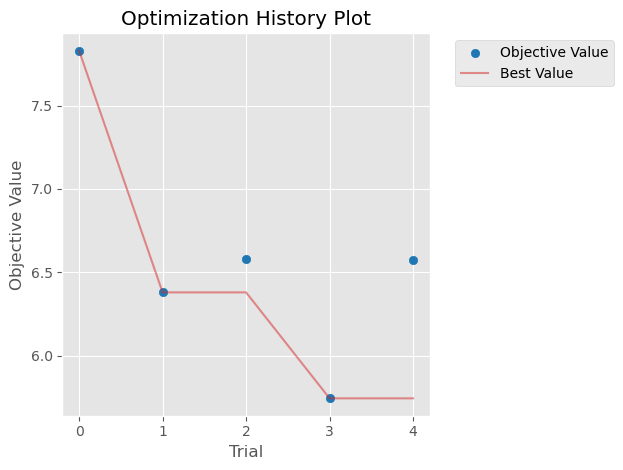

処理時間: 145.47秒


In [3]:
# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

trial_n =5 #Optuna探索試行回数

Optimize_NN(trial_n, X_train, Y_train, device)